# Conditional VAE with Discriminator Loss (cVAE-GAN)

**Hypothesis**

> Adding a discriminator term to the loss function of a Conditional VAE during training increases the sharpness of the reconstructed images.

Training two models on a custom 20×20 MNIST dataset:
1. **Baseline cVAE** - A standard Conditional Variational Autoencoder trained with MSE reconstruction loss and KL-Divergence.
2. **Modified cVAE** - The same architecture, but trained with an additional adversarial discriminator loss to encourage sharper, more realistic outputs.

Both models share identical encoder/decoder architectures with a latent dimension of **z = 7**, ensuring a fair comparison.

## Setup and Imports

Import all required libraries and model definitions. The neural network architectures (`cVAE`, `cDiscriminator`) and the shared loss function (`compute_vae_loss`) are centralised in `models.py` to guarantee structural parity between training and evaluation.

In [1]:
from torch.utils.data import DataLoader
from torchvision.utils import make_grid
from tqdm import tqdm
import copy
import matplotlib.pyplot as plt
import numpy as np
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from models import cVAE, cDiscriminator, compute_vae_loss, load_dataset

# Fix random seed for reproducibility at the top
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)

z_dim = 7
num_classes = 10
bs_train = 1000
nb_epoch = 30

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda:0


## Data Loading

Loading the custom MNIST dataset from the `mnist_custom/` directory. This dataset contains 20×20 pixel handwritten digits (cropped from the standard 28×28 MNIST). The data is split into training and testing sets, with a batch size of 1000.

In [ ]:
# Load the custom 20x20 MNIST dataset from directory
data_custom = load_dataset('mnist_custom')
# Create PyTorch TensorDatasets for train/test splits
train_dataset = torch.utils.data.TensorDataset(data_custom['train_images'], data_custom['train_labels'])
# Load the custom 20x20 MNIST dataset from directory
data_custom = load_dataset('mnist_custom')
test_dataset = torch.utils.data.TensorDataset(data_custom['test_images'], data_custom['test_labels'])

# Wrap datasets in DataLoaders with batch size of 1000
train_dataloader = DataLoader(train_dataset, batch_size=bs_train, shuffle=True, num_workers=0)
test_dataloader = DataLoader(test_dataset, batch_size=bs_train, shuffle=False, num_workers=0)

# Helper function to move batch to device and one-hot encode labels
def get_batch(batch, device, num_classes=10):
    x = batch[0].to(device)
    cond = batch[1].to(device)
    cond = F.one_hot(cond, num_classes=num_classes).float()
    return x, cond

## Dataset Inspection

Let's visually inspect a sample of 10 images from the dataset to verify the data is loaded correctly and understand the visual characteristics of the 20×20 digit images.

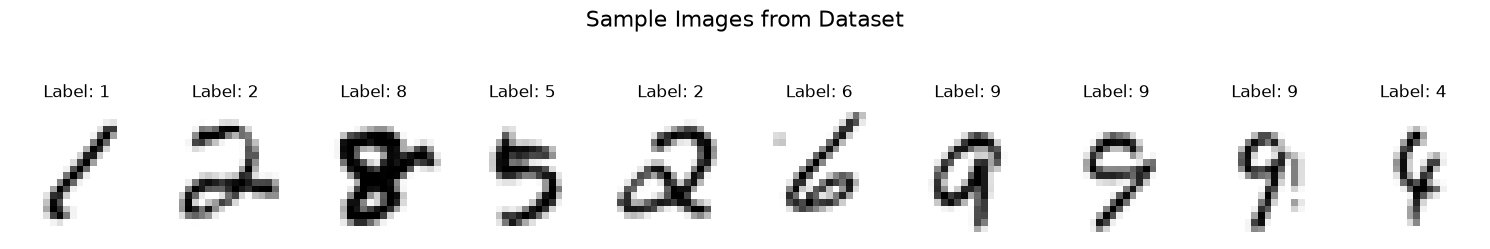

In [3]:
# Examine some samples from the custom dataset
batch_x, batch_y = next(iter(train_dataloader))
fig, axes = plt.subplots(1, 10, figsize=(15, 3))
for i in range(10):
    axes[i].imshow(batch_x[i].squeeze(), cmap='gray')
    axes[i].set_title(f'Label: {batch_y[i].item()}')
    axes[i].axis('off')
plt.suptitle('Sample Images from Dataset', fontsize=16)
plt.tight_layout()
plt.show()

## 1. Baseline cVAE Training

### Architecture
The baseline model is a standard Conditional VAE consisting of:
- **Encoder**: Takes a flattened 20×20 image concatenated with a one-hot class label and maps it to a latent distribution (μ, log σ²) of dimension z=7.
- **Decoder**: Takes a sampled latent vector z concatenated with the class label and reconstructs the 20×20 image.

### Loss Function
$$\mathcal{L}_{VAE} = \text{MSE}(x, \hat{x}_z) + \beta \cdot \text{KL}(z \| p(z))$$

Where β = 0.1 balances reconstruction fidelity against latent space regularisation. The MSE term is scaled by 100 to ensure it dominates early training.

### Training Strategy
- **Optimiser**: AdamW with lr=0.001 and betas=(0.75, 0.99)
- **Early stopping**: Patience of 5 epochs based on validation loss
- **Best model**: Weights from the epoch with the lowest validation loss are saved

In [4]:
# Instantiate the baseline cVAE with z_dim=7 latent dimensions
base_vae = cVAE(z_dim, num_classes).to(device)
# AdamW optimiser with slightly aggressive momentum for faster convergence
opt_base = optim.AdamW(base_vae.parameters(), lr=0.001, betas=(0.75, 0.99))


# Track training and validation losses across epochs
history_base = {'train_loss': [], 'val_loss': []}

# Early stopping configuration
patience = 5
best_val_loss = float('inf')
patience_counter = 0
best_base_weights = None
best_base_epoch = 0

for epoch in range(nb_epoch):
    print(f'----- Epoch {epoch+1}')
    
    base_vae.train()
    total_train_loss = 0
    pbar_train = tqdm(file=sys.stdout, iterable=train_dataloader, unit="batch", desc='training', colour='GREEN', leave=True)
    for batch in pbar_train:
        x, cond = get_batch(batch, device)
        opt_base.zero_grad()
        x_hat, mu, logvar = base_vae(x, cond)
        loss, _, _ = compute_vae_loss(x, x_hat, mu, logvar)
        loss.backward()
        opt_base.step()
        total_train_loss += loss.item()
        
    avg_train = total_train_loss / len(train_dataloader)
    
    base_vae.eval()
    total_val_loss = 0
    pbar_test = tqdm(file=sys.stdout, iterable=test_dataloader, unit="batch", desc=' testing', colour='CYAN', leave=True)
    with torch.no_grad():
        for batch in pbar_test:
            x, cond = get_batch(batch, device)
            x_hat, mu, logvar = base_vae(x, cond)
            loss, _, _ = compute_vae_loss(x, x_hat, mu, logvar)
            total_val_loss += loss.item()
            
    avg_val = total_val_loss / len(test_dataloader)
    
    history_base['train_loss'].append(avg_train)
    history_base['val_loss'].append(avg_val)
    print(f"losses training: {avg_train}, testing: {avg_val}")
    
        # Save best weights based on validation loss
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        best_base_epoch = epoch
        patience_counter = 0
        best_base_weights = copy.deepcopy(base_vae.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping baseline at epoch {epoch+1}!")
            break

print(f"Restoring best baseline weights from epoch {best_base_epoch+1} (Val Loss: {best_val_loss:.2f})")
base_vae.load_state_dict(best_base_weights)
# Persist the best baseline weights for the evaluation notebook
torch.save(base_vae.state_dict(), 'assets/baseline_cvae_weights.pt')

----- Epoch 1
 testing: 100%|██████████| 10/10 [00:00<00:00, 32.52batch/s]
losses training: 9.440816680590311, testing: 5.838942956924439
----- Epoch 2
 testing: 100%|██████████| 10/10 [00:00<00:00, 77.29batch/s]
losses training: 5.374617878595988, testing: 4.892832517623901
----- Epoch 3
 testing: 100%|██████████| 10/10 [00:00<00:00, 74.60batch/s]
losses training: 4.567931056022644, testing: 4.21964316368103
----- Epoch 4
 testing: 100%|██████████| 10/10 [00:00<00:00, 76.79batch/s]
losses training: 4.020230638980865, testing: 3.8425150394439695
----- Epoch 5
 testing: 100%|██████████| 10/10 [00:00<00:00, 76.90batch/s]
losses training: 3.7389128684997557, testing: 3.6382319211959837
----- Epoch 6
 testing: 100%|██████████| 10/10 [00:00<00:00, 32.33batch/s]
losses training: 3.558244939645131, testing: 3.6155168533325197
----- Epoch 7
 testing: 100%|██████████| 10/10 [00:00<00:00, 76.72batch/s]
losses training: 3.4014849225680033, testing: 3.337635564804077
----- Epoch 8
 testing: 100%|█

### Baseline Training Loss Interpretation

The plot below shows the training and validation loss curves for the baseline cVAE. Key observations:
- **Convergence**: Both curves should decrease and plateau, indicating the model has learned to reconstruct digits.
- **Best Epoch**: The vertical dashed line marks epoch 30 with the lowest validation loss, whose weights are saved.
- **Overfitting check**: If the training loss continues to decrease while validation loss increases, it would indicate overfitting.


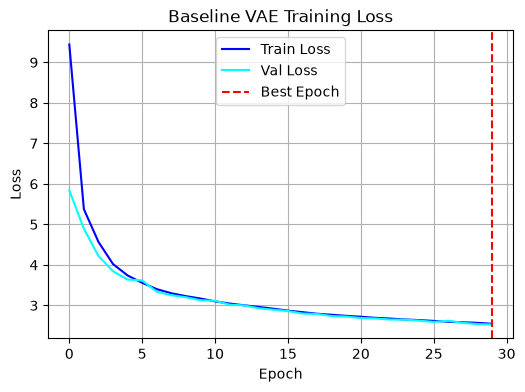

In [ ]:
# Plot Baseline VAE Training Loss
plt.figure(figsize=(6, 4))
plt.plot(history_base['train_loss'], label='Train Loss', color='blue')
plt.plot(history_base['val_loss'], label='Val Loss', color='cyan')
plt.axvline(x=best_base_epoch, color='red', linestyle='--', label='Best Epoch')
plt.title('Baseline VAE Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.savefig('plot/dev_base_loss.png')
plt.show()

## 2. Modified cVAE Training (with Discriminator Loss)

### Architecture Extension
The modified model adds a **Conditional Discriminator** network that learns to distinguish between real images and VAE-generated reconstructions. This creates an adversarial training dynamic.

### Loss Functions (as specified in the task)

**Discriminator Loss** - Trains the discriminator to correctly classify real vs. generated images:
$$\mathcal{L}_D = \mathbb{E}_x[\log(1 - D(x))] + \mathbb{E}_z[\log(D(G(z)))]$$

**Generator Loss** - Encourages the VAE to produce outputs that fool the discriminator:
$$\mathcal{L}_G = \mathbb{E}_z[\log(1 - D(G(z)))]$$

**Combined VAE-GAN Loss** — The total generator objective blends the standard VAE loss with the adversarial term:
$$\mathcal{L}_{total} = \mathcal{L}_{VAE} + \alpha \cdot \mathcal{L}_G$$

Where α = 0.5 is the adversarial weight, balancing reconstruction quality with perceptual sharpness.

### Training Strategy
- The **discriminator** and **VAE (generator)** are trained alternately within each batch.
- The discriminator uses a lower learning rate (0.0005) with different Adam betas to stabilise the adversarial dynamics.
- Early stopping is applied on the combined validation loss.

In [ ]:
# Instantiate the modified cVAE (same architecture as baseline)
mod_vae = cVAE(z_dim, num_classes).to(device)
# Instantiate the adversarial discriminator network
discriminator = cDiscriminator(num_classes).to(device)

# Separate optimisers for generator (VAE) and discriminator
opt_mod = optim.AdamW(mod_vae.parameters(), lr=0.001, betas=(0.75, 0.99))
# Lower learning rate + different betas for discriminator stability
opt_disc = optim.AdamW(discriminator.parameters(), lr=0.0005, betas=(0.5, 0.999))

bce_loss = nn.BCELoss()
# Weight for adversarial loss contribution to total generator loss
adv_weight = 0.5 
eps = 1e-8  # Numerical stability for log computations

def compute_accuracy(preds, targets):
    return ((preds > 0.5).float() == targets).float().mean().item() * 100.0

history_mod = {
    'train_v_loss': [], 'val_v_loss': [], 
    'train_d_loss': [], 'val_d_loss': [],
    'train_d_acc': [], 'val_d_acc': []
}

best_val_loss = float('inf')
patience_counter = 0
best_mod_weights = None
best_mod_epoch = 0

for epoch in range(nb_epoch):
    print(f'----- Epoch {epoch+1}')
    
    mod_vae.train()
    discriminator.train()
    total_vae_loss, total_disc_loss, total_disc_acc = 0, 0, 0
    
    pbar_train = tqdm(file=sys.stdout, iterable=train_dataloader, unit="batch", desc='training', colour='GREEN', leave=True)
    for batch in pbar_train:
        x, cond = get_batch(batch, device)
        batch_size = x.size(0)
        
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)
        
        # Train Discriminator
        opt_disc.zero_grad()
        real_preds = discriminator(x, cond)
        
        with torch.no_grad():
            x_hat, _, _ = mod_vae(x, cond)
        fake_preds = discriminator(x_hat.detach(), cond)
        
        # L_D = E_x[log(1 - D(x))] + E_z[log(D(G(z)))]
        d_loss = torch.mean(torch.log(1 - real_preds + eps)) + torch.mean(torch.log(fake_preds + eps))
        d_loss.backward()
        opt_disc.step()
        
        batch_d_acc = (compute_accuracy(real_preds, real_labels) + compute_accuracy(fake_preds, fake_labels)) / 2

        # Train Generator (VAE)
        opt_mod.zero_grad()
        x_hat, mu, logvar = mod_vae(x, cond)
        v_loss_standard, recon, kl = compute_vae_loss(x, x_hat, mu, logvar)
        
        fake_preds_for_gen = discriminator(x_hat, cond)

        # L_G = E_z[log(1 - D(G(z)))]
        g_loss_adv = torch.mean(torch.log(1 - fake_preds_for_gen + eps))
        
        # Total generator loss = standard VAE loss + weighted adversarial loss
        g_loss = v_loss_standard + adv_weight * g_loss_adv
        g_loss.backward()
        opt_mod.step()
        
        total_vae_loss += g_loss.item()
        total_disc_loss += d_loss.item()
        total_disc_acc += batch_d_acc
        
    avg_train_v_loss = total_vae_loss / len(train_dataloader)
    avg_train_d_loss = total_disc_loss / len(train_dataloader)
    avg_train_d_acc = total_disc_acc / len(train_dataloader)
    
    mod_vae.eval()
    discriminator.eval()
    total_val_v_loss, total_val_d_loss, total_val_d_acc = 0, 0, 0
    pbar_test = tqdm(file=sys.stdout, iterable=test_dataloader, unit="batch", desc=' testing', colour='CYAN', leave=True)
    with torch.no_grad():
        for batch in pbar_test:
            x, cond = get_batch(batch, device)
            x_hat, mu, logvar = mod_vae(x, cond)
            v_loss_standard, _, _ = compute_vae_loss(x, x_hat, mu, logvar)
            
            real_preds = discriminator(x, cond)
            fake_preds = discriminator(x_hat, cond)
            d_loss_val = torch.mean(torch.log(1 - real_preds + eps)) + torch.mean(torch.log(fake_preds + eps))
            acc_val = (compute_accuracy(real_preds, torch.ones_like(real_preds)) + compute_accuracy(fake_preds, torch.zeros_like(fake_preds))) / 2
            
            g_loss_adv = torch.mean(torch.log(1 - discriminator(x_hat, cond) + eps))
            total_val_v_loss += (v_loss_standard + adv_weight * g_loss_adv).item()
            total_val_d_loss += d_loss_val.item()
            total_val_d_acc += acc_val
            
    avg_val_v_loss = total_val_v_loss / len(test_dataloader)
    avg_val_d_loss = total_val_d_loss / len(test_dataloader)
    avg_val_d_acc = total_val_d_acc / len(test_dataloader)
    
    history_mod['train_v_loss'].append(avg_train_v_loss)
    history_mod['val_v_loss'].append(avg_val_v_loss)
    history_mod['train_d_loss'].append(avg_train_d_loss)
    history_mod['val_d_loss'].append(avg_val_d_loss)
    history_mod['train_d_acc'].append(avg_train_d_acc)
    history_mod['val_d_acc'].append(avg_val_d_acc)
    
    print(f"losses training: {avg_train_v_loss}, testing: {avg_val_v_loss} (D-Acc: {avg_val_d_acc:.1f}%)")
    
    if avg_val_v_loss < best_val_loss:
        best_val_loss = avg_val_v_loss
        best_mod_epoch = epoch
        patience_counter = 0
        best_mod_weights = copy.deepcopy(mod_vae.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping modified at epoch {epoch+1}!")
            break

print(f"Restoring best modified weights from epoch {best_mod_epoch+1} (Val Loss: {best_val_loss:.2f})")
mod_vae.load_state_dict(best_mod_weights)

# Save the best modified weights for the evaluation notebook
torch.save(mod_vae.state_dict(), 'assets/modified_cvae_weights.pt')

----- Epoch 1
training:   0%|          | 0/60 [00:00<?, ?batch/s]

 testing: 100%|██████████| 10/10 [00:00<00:00, 26.21batch/s]
losses training: 4.91581871509552, testing: -3.1544639110565185 (D-Acc: 50.0%)
----- Epoch 2
 testing: 100%|██████████| 10/10 [00:00<00:00, 49.62batch/s]
losses training: -3.579708790779114, testing: -3.8859489440917967 (D-Acc: 50.0%)
----- Epoch 3
 testing: 100%|██████████| 10/10 [00:00<00:00, 49.94batch/s]
losses training: -4.216462071736654, testing: -4.567358303070068 (D-Acc: 50.0%)
----- Epoch 4
 testing: 100%|██████████| 10/10 [00:00<00:00, 49.15batch/s]
losses training: -4.892588766415914, testing: -5.184036636352539 (D-Acc: 50.0%)
----- Epoch 5
 testing: 100%|██████████| 10/10 [00:00<00:00, 48.88batch/s]
losses training: -5.320157297452291, testing: -5.469131994247436 (D-Acc: 50.0%)
----- Epoch 6
 testing: 100%|██████████| 10/10 [00:00<00:00, 50.08batch/s]
losses training: -5.546762371063233, testing: -5.625831508636475 (D-Acc: 50.0%)
----- Epoch 7
 testing: 100%|██████████| 10/10 [00:00<00:00, 46.50batch/s]
losses tr

### Modified Training Loss and Discriminator Accuracy Interpretation

The two plots below track the modified model's training dynamics:

**Left - VAE Loss**: The combined ℒ_VAE + α·ℒ_G loss. Compared to the baseline, this loss may be higher because the generator is simultaneously trying to minimise reconstruction error AND fool the discriminator.

**Right - Discriminator Accuracy**: Tracks how well the discriminator can distinguish real from generated images.
- **~50%** accuracy indicates equilibrium — the generator is producing images indistinguishable from real ones.
- **~100%** accuracy means the discriminator is winning — generated images are easily identifiable as fake.
- A healthy training run should show accuracy starting high and gradually decreasing toward 50-70% as the generator improves.


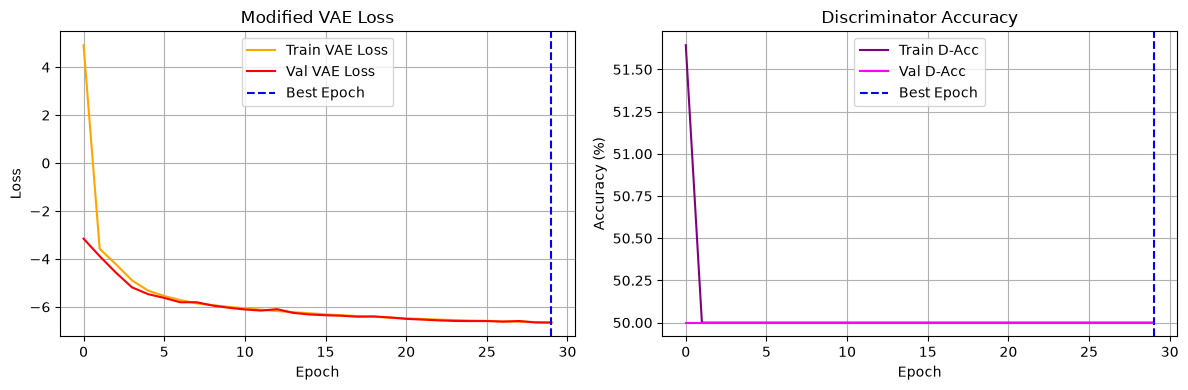

In [7]:
# Plot Modified VAE Training Loss and Discriminator Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history_mod['train_v_loss'], label='Train VAE Loss', color='orange')
ax1.plot(history_mod['val_v_loss'], label='Val VAE Loss', color='red')
ax1.axvline(x=best_mod_epoch, color='blue', linestyle='--', label='Best Epoch')
ax1.set_title('Modified VAE Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(history_mod['train_d_acc'], label='Train D-Acc', color='purple')
ax2.plot(history_mod['val_d_acc'], label='Val D-Acc', color='magenta')
ax2.axvline(x=best_mod_epoch, color='blue', linestyle='--', label='Best Epoch')
ax2.set_title('Discriminator Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)
plt.tight_layout()
plt.savefig('plot/dev_mod_loss.png')
plt.show()

## Reconstruction Comparison

To qualitatively evaluate both models, we pass the same test batch through both the baseline and modified VAE and display the reconstructions side by side:
- **Row 1 (Original)**: The ground-truth test images
- **Row 2 (Baseline)**: Reconstructions from the standard cVAE — typically blurry due to the regression-to-the-mean problem
- **Row 3 (Modified)**: Reconstructions from the discriminator-enhanced cVAE — expected to show sharper edges and cleaner strokes

This visual comparison directly addresses the hypothesis: if the modified model produces visibly sharper reconstructions, it supports the claim that adversarial training improves image quality.

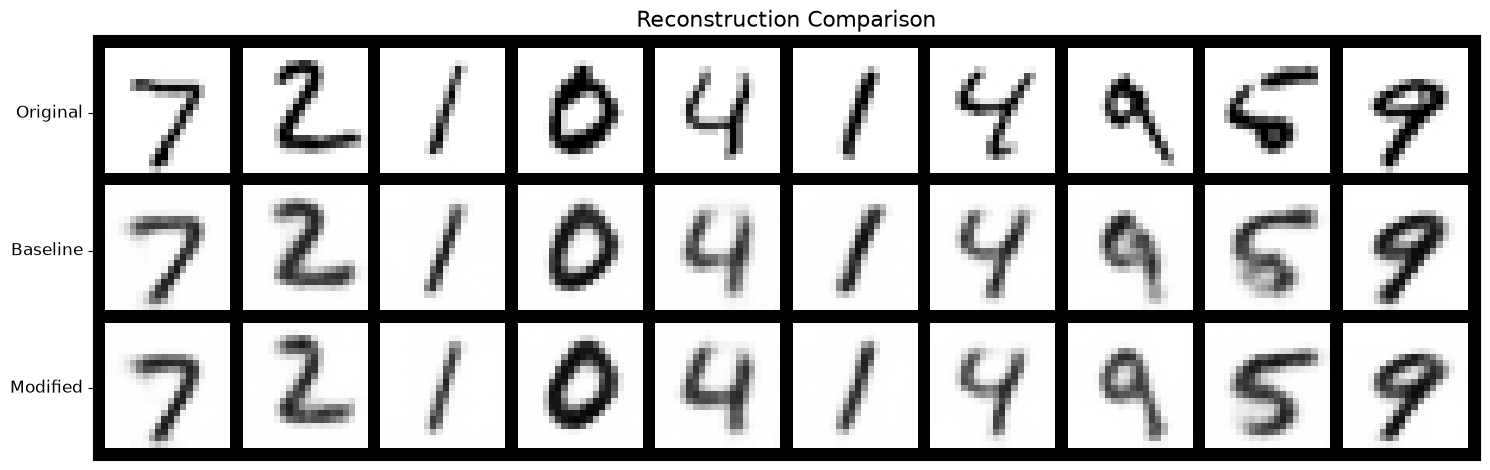

In [8]:
# Compare Original vs Baseline vs Modified Reconstructions in one plot
base_vae.eval()
mod_vae.eval()
batch = next(iter(test_dataloader))
x_test, cond_test = get_batch(batch, device)
with torch.no_grad():
    base_x_hat, _, _ = base_vae(x_test, cond_test)
    mod_x_hat, _, _ = mod_vae(x_test, cond_test)
n_display = 10
display_images = torch.cat((x_test[:n_display], base_x_hat[:n_display], mod_x_hat[:n_display]))
grid = make_grid(display_images, nrow=n_display).permute(1, 2, 0).cpu().numpy()
plt.figure(figsize=(15, 6))
plt.imshow(grid, cmap='gray')
plt.yticks([12, 34, 56], ['Original', 'Baseline', 'Modified'], rotation=0, va='center', fontsize=12)
plt.xticks([])
plt.title('Reconstruction Comparison', fontsize=16)
plt.tight_layout()
plt.savefig('plot/dev_reconstructions.png')
plt.show()


## Conditional Generation Comparison

We perform conditional sampling: for each of the 10 digit classes (0–9), we generate 12 samples from each model using the **same random latent vectors z**. This ensures a direct one-to-one comparison.

- **Left half (columns 1–12)**: Baseline cVAE generations
- **Right half (columns 13–24)**: Modified cVAE generations
- **Black separator line**: Divides the two model outputs

Look for:
- **Sharpness**: Are the modified digits' strokes cleaner and more defined?
- **Diversity**: Does each model produce varied samples within each class?
- **Consistency**: Do the generated digits clearly match their conditioned class label?

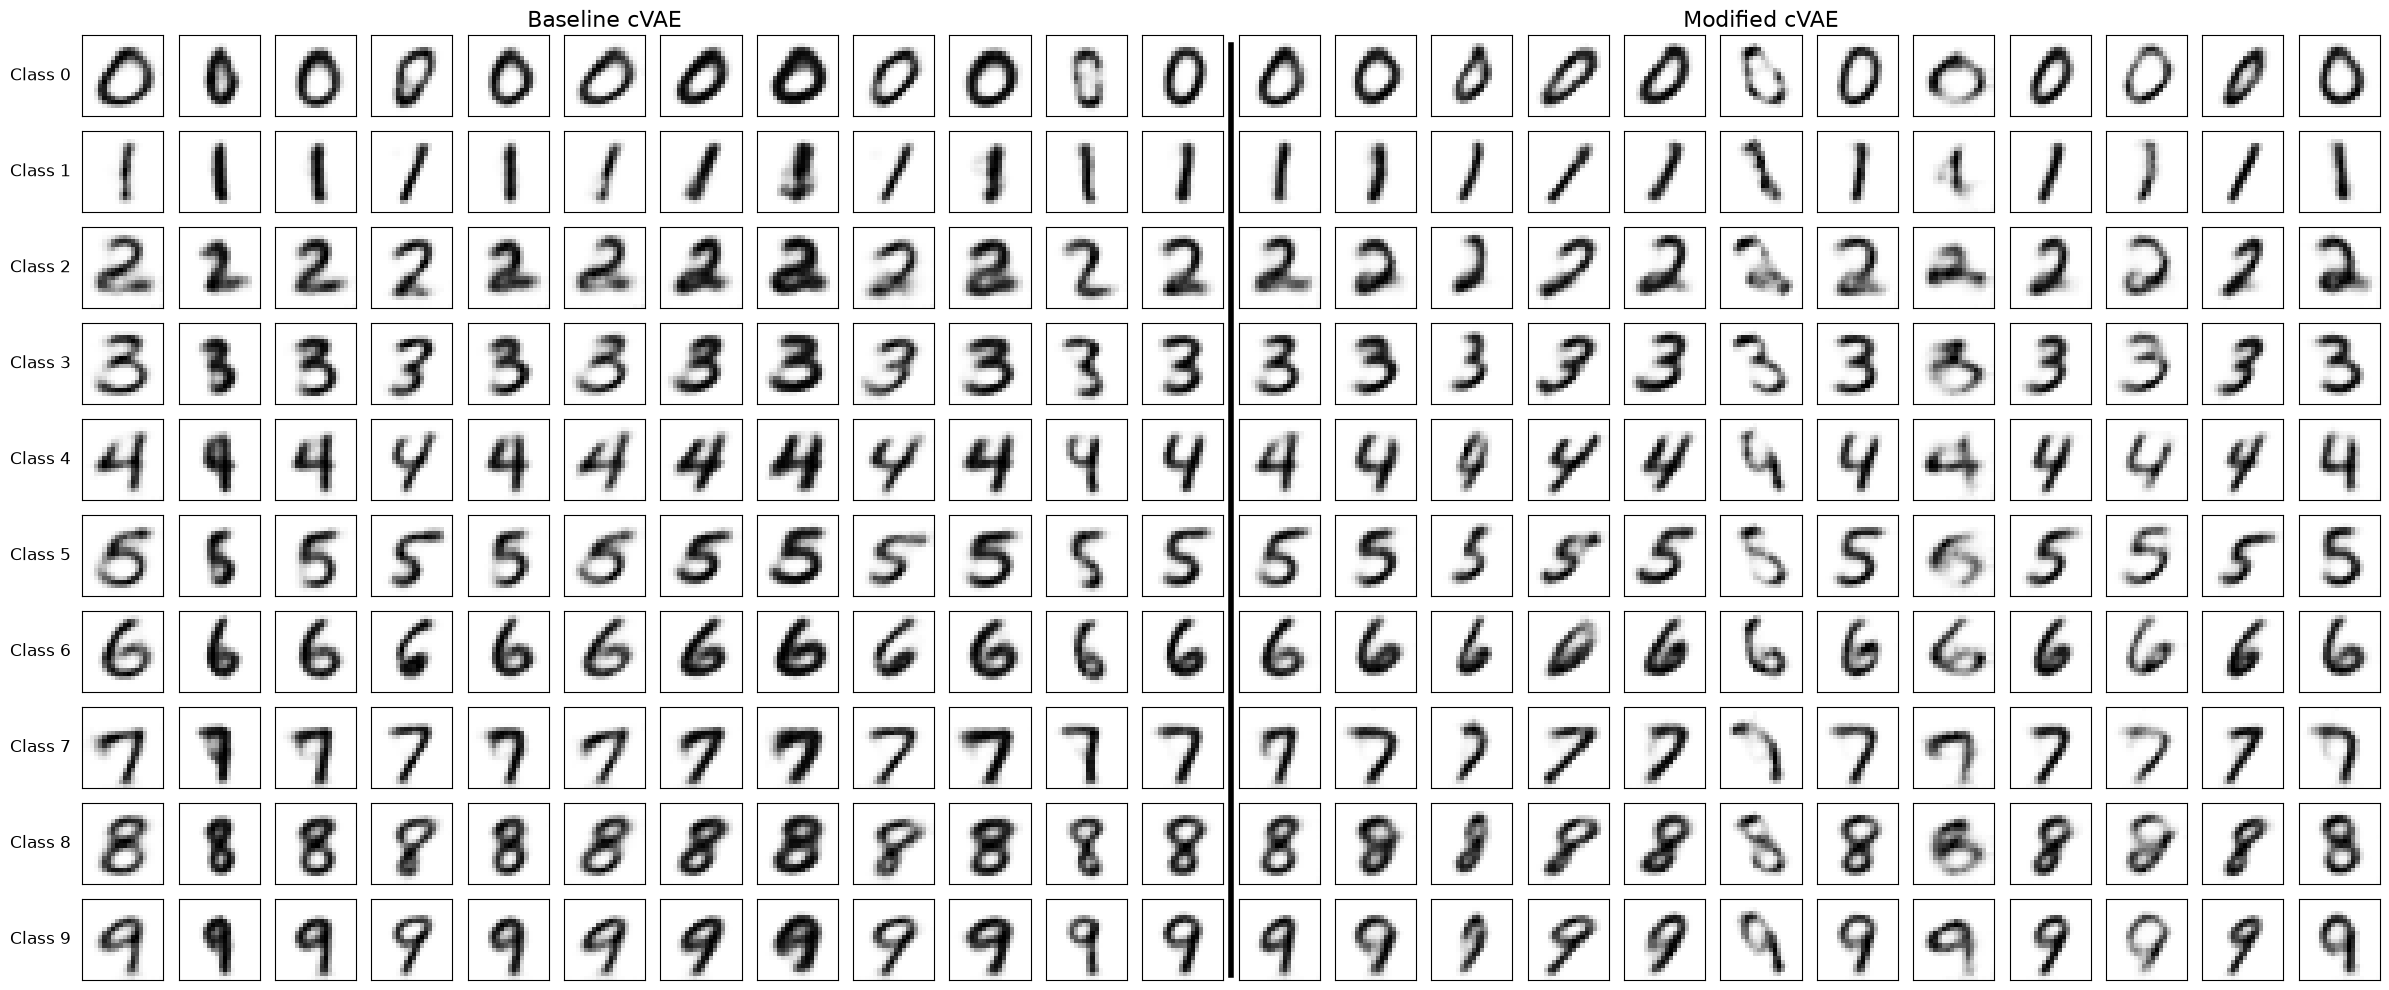

In [9]:
# Conditional Generation Side-by-Side (12x10 Grid each -> 24x10 Total)
def get_gen_grid(model, num_samples=12):
    all_xhat = []
    z_cond = torch.randn(num_samples, z_dim).to(device)
    for c in range(10):
        cond = F.one_hot(torch.tensor([c]*num_samples), num_classes=10).float().to(device)
        with torch.no_grad():
            x_hat, _, _ = model(z_cond, cond) if hasattr(model, 'decode') == False else (model.decode(z_cond, cond), None, None)
            if isinstance(x_hat, tuple): x_hat = x_hat[0]
        all_xhat.append(x_hat.cpu())
    return torch.stack(all_xhat) # [10, 12, 1, 20, 20]

base_gen_grid = get_gen_grid(base_vae)
mod_gen_grid = get_gen_grid(mod_vae)

fig, axes = plt.subplots(10, 24, figsize=(24, 10))
for c in range(10):
    for i in range(12):
        # Baseline
        axes[c, i].imshow(base_gen_grid[c, i].squeeze(), cmap='gray')
        axes[c, i].set_xticks([])
        axes[c, i].set_yticks([])
        if i == 0: axes[c, i].set_ylabel(f'Class {c}', rotation=0, labelpad=30, va='center', fontsize=12)
        if c == 0 and i == 5: axes[c, i].set_title('Baseline cVAE', fontsize=16)
        
        # Modified
        axes[c, i+12].imshow(mod_gen_grid[c, i].squeeze(), cmap='gray')
        axes[c, i+12].set_xticks([])
        axes[c, i+12].set_yticks([])
        if c == 0 and i == 5: axes[c, i+12].set_title('Modified cVAE', fontsize=16)

plt.tight_layout()
import matplotlib.lines as lines
pos11 = axes[0, 11].get_position()
pos12 = axes[0, 12].get_position()
mid_x = (pos11.x1 + pos12.x0) / 2
line = lines.Line2D([mid_x, mid_x], [0.02, 0.95], transform=fig.transFigure, color='black', linewidth=4)
fig.add_artist(line)
plt.savefig('plot/dev_generated_side_by_side.png')
plt.show()
